# 04 - Geometric difference (week 2)
Owner: **Haider**

The geometric difference compares a classical kernel table $K^C$ with a quantum kernel table $K^Q$ built on the **same training images**:

$$g(K^{C}\|K^{Q}) = \sqrt{\Big\|\sqrt{K^{Q}}\,(K^{C})^{-1}\sqrt{K^{Q}}\Big\|_{\infty}}$$

Classical kernel tables are often nearly singular, so, as in Huang et al. (Appendix F.3), we report the regularised version

$$g_{\mathrm{gen}}(\lambda) = \sqrt{\Big\|\sqrt{K^{Q}}\sqrt{K^{C}}\,(K^{C}+\lambda I)^{-2}\sqrt{K^{C}}\sqrt{K^{Q}}\Big\|},\qquad g_{\mathrm{tra}}(\lambda) = \lambda\sqrt{\Big\|\sqrt{K^{Q}}\,(K^{C}+\lambda I)^{-2}\sqrt{K^{Q}}\Big\|}$$

$g_{\mathrm{gen}}$ equals the ideal $g$ when $\lambda = 0$. Huang et al. choose the largest $\lambda$ with $g_{\mathrm{tra}} \le 0.045$; with only 2-8 features our classical kernel tables are effectively low-rank, so that rule is rarely satisfiable and $g$ then grows like $1/\sqrt{\lambda}$. We therefore report $g_{\mathrm{gen}}$ at **one fixed, pre-declared $\lambda = 0.1$** (10% of the mean eigenvalue of the trace-normalised $K^C$) for every comparison, together with the $\lambda$ curve and how often Huang's rule is feasible.

Small $g$: the quantum kernel sees the data like the classical one, so it cannot have an advantage. Large $g$: an advantage is possible (not guaranteed).

- Kernels are trace-normalised; $\lambda$ is fixed in advance and never chosen by accuracy.
- $K^Q$: **ideal (exact)** quantum kernels on training images, with each model's tuned hyperparameters.
- $K^C$: the tuned RBF, polynomial and linear kernels from notebook 01.
- Paired gap per seed: $\Delta A = A^Q - A^{C^\ast}$ (sampled quantum test accuracy minus the best classical model chosen by training CV).
- Fidelity pairs are added automatically once notebook 02's sweep has saved them.

In [7]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src.common import get_split, make_preprocessor, result_path, RESULTS, SEEDS
from src.baselines import classical_gram
from src.geometry import geometric_difference, huang_lambda, g_sensitivity, LAM_FIXED

## 1. Settings

In [8]:
N_LIST = [2, 4, 6, 8]
KINDS = {"SVM RBF (tuned)": "rbf", "SVM polynomial (tuned)": "poly", "SVM linear (tuned)": "linear"}

def load_json(kind, name, seed, n):
    p = result_path(kind, name, seed, n, "json")
    return json.loads(p.read_text()) if p.exists() else None

def fidelity_ready(n):
    return all(result_path("kernels", "fidelity_exact_train", s, n, "npy").exists()
               and result_path("tables", "fidelity_v2", s, n, "json").exists() for s in SEEDS)

QUANTUM = {"projected": ("projected_exact_train", "projected_v2")}
print("fidelity sweep available for n =", [n for n in N_LIST if fidelity_ready(n)] or "none yet")

fidelity sweep available for n = [2, 4, 6, 8]


## 2. Geometric difference for every quantum-classical pair

In [9]:
geo_runs = []
for n in N_LIST:
    qkinds = dict(QUANTUM)
    if fidelity_ready(n):
        qkinds["fidelity"] = ("fidelity_exact_train", "fidelity_v2")
    for seed in SEEDS:
        base = load_json("tables", "baselines_v2", seed, n)
        Xtr, ytr, Xte, yte = get_split(seed)
        Ftr = make_preprocessor(n, alpha=1.0)(Xtr)(Xtr)          # same features as notebook 01
        KC = {name: classical_gram(kind, base["results"][name]["params"], Ftr)
              for name, kind in KINDS.items()}
        c_star = base["c_star"]
        acc_c_star = base["results"][c_star]["acc"]
        for q, (kfile, tfile) in qkinds.items():
            KQ = np.load(result_path("kernels", kfile, seed, n, "npy"))
            qres = load_json("tables", tfile, seed, n)
            g = {}
            for name, K in KC.items():
                val, gtra = geometric_difference(K, KQ)
                g[name] = dict(g=val, g_tra=gtra, huang_lambda=huang_lambda(K, KQ))
            out = dict(seed=seed, n_qubits=n, quantum=q, c_star=c_star, g=g,
                       g_c_star=g[c_star]["g"],
                       sensitivity_c_star={str(k): v for k, v in g_sensitivity(KC[c_star], KQ).items()},
                       acc_quantum=qres["sampled"]["acc"], acc_c_star=acc_c_star,
                       delta_A=qres["sampled"]["acc"] - acc_c_star)
            result_path("tables", f"geometry_{q}_v2", seed, n, "json").write_text(json.dumps(out, indent=2))
            geo_runs.append(out)
    print(f"n={n}: done ({', '.join(qkinds)})")

n=2: done (projected, fidelity)
n=4: done (projected, fidelity)
n=6: done (projected, fidelity)
n=8: done (projected, fidelity)


## 3. Results

In [10]:
short = {"SVM RBF (tuned)": "RBF", "SVM polynomial (tuned)": "poly", "SVM linear (tuned)": "linear"}
for q in sorted({r["quantum"] for r in geo_runs}):
    rows = [r for r in geo_runs if r["quantum"] == q]
    ns = sorted({r["n_qubits"] for r in rows})
    print(f"=== {q} kernel: g_gen at lambda = {LAM_FIXED}, mean +- std over {len(SEEDS)} seeds ===")
    print(f"{'pair':<18}" + "".join(f"{'n=' + str(n):>16}" for n in ns))
    for name in KINDS:
        line = f"{q[:4] + ' vs ' + short[name]:<18}"
        for n in ns:
            v = np.array([r["g"][name]["g"] for r in rows if r["n_qubits"] == n])
            line += f"{v.mean():>10.2f} +-{v.std():.2f}"
        print(line)
    for label, key in [("g vs C*", "g_c_star"), ("Delta A", "delta_A")]:
        line = f"{label:<18}"
        for n in ns:
            v = np.array([r[key] for r in rows if r["n_qubits"] == n])
            line += f"{v.mean():>10.3f} +-{v.std():.3f}"
        print(line)
    feas = [r["g"][name]["huang_lambda"] is not None for r in rows for name in KINDS]
    print(f"lambda = {LAM_FIXED} for all pairs; Huang's rule (g_tra <= 0.045) feasible in "
          f"{sum(feas)}/{len(feas)} pairs\n")

=== fidelity kernel: g_gen at lambda = 0.1, mean +- std over 5 seeds ===
pair                           n=2             n=4             n=6             n=8
fide vs RBF             2.61 +-0.96      2.83 +-0.85      2.45 +-0.70      2.35 +-0.60
fide vs poly            2.90 +-0.80      2.80 +-0.91      3.89 +-1.41      3.90 +-1.25
fide vs linear          0.57 +-0.10      0.94 +-0.22      1.24 +-0.20      1.28 +-0.25
g vs C*                2.870 +-0.813     2.830 +-0.847     3.538 +-1.556     2.810 +-1.673
Delta A                0.035 +-0.049    -0.030 +-0.043    -0.035 +-0.044    -0.030 +-0.102
lambda = 0.1 for all pairs; Huang's rule (g_tra <= 0.045) feasible in 27/60 pairs

=== projected kernel: g_gen at lambda = 0.1, mean +- std over 5 seeds ===
pair                           n=2             n=4             n=6             n=8
proj vs RBF             2.68 +-1.21      2.95 +-0.27      3.23 +-0.39      3.01 +-0.34
proj vs poly            2.88 +-0.72      2.97 +-0.92      3.49 +-0.67     

**Reading the table:** $\Delta A > 0$ means the quantum kernel beat the best classical model on that seed. Our rule (synopsis) counts an improvement only if mean $\Delta A$ exceeds its standard deviation.

## 4. Sensitivity of $g_{\mathrm{gen}}$ to $\lambda$ (pair with $C^\ast$, reported only)

In [11]:
for q in sorted({r["quantum"] for r in geo_runs}):
    rows = [r for r in geo_runs if r["quantum"] == q]
    print(f"=== {q} vs C*: mean g over seeds for each lambda ===")
    lam_keys = list(rows[0]["sensitivity_c_star"].keys())
    print(f"{'n':<6}" + "".join(f"{float(k):>10.0e}" for k in lam_keys))
    for n in sorted({r["n_qubits"] for r in rows}):
        sub = [r for r in rows if r["n_qubits"] == n]
        print(f"{n:<6}" + "".join(f"{np.mean([r['sensitivity_c_star'][k] for r in sub]):>10.2f}"
                                  for k in lam_keys))

=== fidelity vs C*: mean g over seeds for each lambda ===
n          1e-03     1e-02     1e-01     1e+00
2           4.52      3.32      2.87      1.91
4          16.66      5.60      2.83      1.22
6          11.86      5.65      3.54      1.84
8           5.88      4.00      2.81      1.67
=== projected vs C*: mean g over seeds for each lambda ===
n          1e-03     1e-02     1e-01     1e+00
2           9.39      3.87      3.02      1.88
4          24.26      7.70      2.95      1.27
6          20.66      7.77      3.56      1.32
8          12.82      5.45      3.19      1.61


## 5. Figures

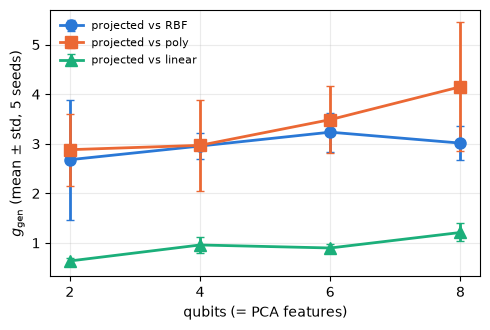

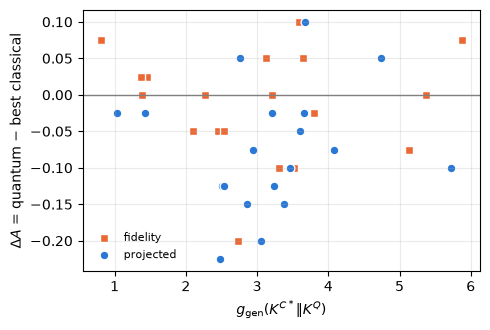

saved figures to E:\LUMS\Semester 3\Quantum Machine Learning\Project\AI631-Projected-Quantum-Kernels\results\figures


In [12]:
COLORS = {"SVM RBF (tuned)": "#2a78d6", "SVM polynomial (tuned)": "#eb6834", "SVM linear (tuned)": "#1baf7a"}
MARKERS = {"SVM RBF (tuned)": "o", "SVM polynomial (tuned)": "s", "SVM linear (tuned)": "^"}
QCOLORS = {"projected": "#2a78d6", "fidelity": "#eb6834"}
QMARKERS = {"projected": "o", "fidelity": "s"}
figdir = RESULTS / "figures"
figdir.mkdir(parents=True, exist_ok=True)

rows = [r for r in geo_runs if r["quantum"] == "projected"]
fig, ax = plt.subplots(figsize=(5, 3.4))
for name in KINDS:
    m = [np.mean([r["g"][name]["g"] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
    s = [np.std([r["g"][name]["g"] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
    ax.errorbar(N_LIST, m, yerr=s, color=COLORS[name], marker=MARKERS[name], markersize=8,
                linewidth=2, capsize=3, label="projected vs " + short[name])
ax.set_xlabel("qubits (= PCA features)")
ax.set_ylabel(r"$g_{\mathrm{gen}}$ (mean $\pm$ std, 5 seeds)")
ax.set_xticks(N_LIST)
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(figdir / "g_vs_qubits_projected.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(5, 3.4))
for q in sorted({r["quantum"] for r in geo_runs}):
    rq = [r for r in geo_runs if r["quantum"] == q]
    ax.scatter([r["g_c_star"] for r in rq], [r["delta_A"] for r in rq], s=40,
               color=QCOLORS[q], marker=QMARKERS[q], edgecolor="white", linewidth=1, label=q)
ax.axhline(0, color="0.5", linewidth=1)
ax.set_xlabel(r"$g_{\mathrm{gen}}(K^{C^\ast}\|K^Q)$")
ax.set_ylabel(r"$\Delta A$ = quantum $-$ best classical")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(figdir / "deltaA_vs_g_original.png", dpi=200)
plt.show()
print("saved figures to", figdir)